# P2.21 — Which associations survive controls, and which designs test themselves?

**Question:** M3 (which factors are associated with price growth, and which relationships have a credible causal identification
strategy?). A synthesis of results already in the project; it adds no new estimate, only one reading rule applied the same way
everywhere.

**Part 1, ladders.** Each driver is followed through the specifications of the notebook that tested it, from the least to the most
controlled (same district, then coast and density, then region-year effects or the foreign-resident change), using the tables those
notebooks saved. By the rule fixed through phase 2, a driver matters if its coefficient is below p = 0.05 with one sign at *every*
rung (`holds`); `fades` is significant first and not last. **Part 2, design checks.** A relationship can support causal language only
if a design tests its own identifying assumption and the assumption survives. The three designs of the project that have such a test
are read side by side.

**Reading rule, fixed before looking:** a relationship has a credible causal identification only if it is in a design check, the
check does not reject the assumption *and* the effect is distinguishable from zero. A ladder that holds is an adjusted association,
however robust. Outcome throughout: the log change of price-to-income (`p2_02` panel 2016-2023; cross-sections 2016-2024 or 2016-2023).

In [1]:
import numpy as np
import pandas as pd

from pthousing.analysis import evidence as ev
from pthousing.config import TABLES
from pthousing.viz import charts, style

style.apply_style()
P2, P3 = TABLES / "p2", TABLES / "p3"
tables = {
    name: pd.read_csv(P2 / f"{name}.csv")
    for name in (
        "fe_regressions_pti",
        "nationality_regressions_pti",
        "synthesis_joint_model",
        "second_homes_cross_section",
        "age_structure_associations",
        "household_size_associations",
    )
}

## Step 1 — The ladders
One row per driver. `FE` ladders go from municipality and year effects to municipality and region-year effects (panel,
`p2_02`, `p2_14`); `cross-section` ladders from the same district to coast and density class (`p2_07`, `p2_06`) and to the foreign-resident
change (`p2_11`, `p2_20`).

In [2]:
FE = ["Municipality + year effects", "Municipality + region-year effects"]
RENT = ["Mainland, with rentals", "Mainland, with rentals, region-year"]
SYN = ["Same district", "Same district, coast and density"]
AGE25 = [
    "25-44 share, same district",
    "25-44 share, + coast and density",
    "25-44 share, + foreign residents",
]
AGE65 = [
    "65+ share, same district",
    "65+ share, + coast and density",
    "65+ share, + foreign residents",
]
ONE = [
    "one-person share, same district",
    "one-person share, + coast and density",
    "one-person share, + 65+ and foreign residents",
]
SIZE = [
    "persons per household, same district",
    "persons per household, + coast and density",
    "persons per household, + 65+ and foreign residents",
]
SECOND = ["Change, same district", "Change, + coast and density"]
LADDERS = [
    ("Foreign residents", "panel FE", "fe_regressions_pti", "foreign_change_pct", FE),
    ("Completions", "panel FE", "fe_regressions_pti", "completions_per_1000", FE),
    ("Other population change", "panel FE", "fe_regressions_pti", "pop_change_ex_foreign_pct", FE),
    ("Share aged 65+", "panel FE", "fe_regressions_pti", "pop_65plus_pct", FE),
    ("Short-term rentals", "panel FE", "fe_regressions_pti", "al_per_1000", RENT),
    ("Brazilian residents", "panel FE", "nationality_regressions_pti", "fc_brazil_pct", FE),
    ("Lusophone Africa residents", "panel FE", "nationality_regressions_pti", "fc_palop_pct", FE),
    ("UK residents", "panel FE", "nationality_regressions_pti", "fc_uk_pct", FE),
    ("Chinese residents", "panel FE", "nationality_regressions_pti", "fc_china_pct", FE),
    (
        "Eastern European residents",
        "panel FE",
        "nationality_regressions_pti",
        "fc_east_europe_pct",
        FE,
    ),
    (
        "Foreign residents (joint model)",
        "cross-section",
        "synthesis_joint_model",
        "foreign_change_pct",
        SYN,
    ),
    ("Household growth", "cross-section", "synthesis_joint_model", "households_change_pct", SYN),
    ("Dwelling growth", "cross-section", "synthesis_joint_model", "dwellings_change_pct", SYN),
    ("Second homes", "cross-section", "second_homes_cross_section", "secondary_2021_pct", SECOND),
    (
        "Share aged 25-44",
        "cross-section",
        "age_structure_associations",
        "age_25_44_pct_change_pp",
        AGE25,
    ),
    (
        "Share aged 65+ (change)",
        "cross-section",
        "age_structure_associations",
        "age_65plus_pct_change_pp",
        AGE65,
    ),
    (
        "One-person households",
        "cross-section",
        "household_size_associations",
        "one_person_change_pp",
        ONE,
    ),
    ("Persons per household", "cross-section", "household_size_associations", "size_change", SIZE),
]
rows, detail = [], []
for driver, design, name, term, specs in LADDERS:
    r = ev.rungs(tables[name], term, specs)
    r.insert(0, "driver", driver)
    detail.append(r)
    ok = r.dropna(subset=["p"])
    rows.append(
        {
            "driver": driver,
            "design": design,
            "rungs_n": len(ok),
            "first_p": ok["p"].iloc[0] if len(ok) else np.nan,
            "last_p": ok["p"].iloc[-1] if len(ok) else np.nan,
            "first_coef_per_sd": ok["coef_per_sd"].iloc[0] if len(ok) else np.nan,
            "last_coef_per_sd": ok["coef_per_sd"].iloc[-1] if len(ok) else np.nan,
            "class": ev.classify(r),
        }
    )
ladder = pd.DataFrame(rows)
rung_detail = pd.concat(detail, ignore_index=True)
style.save_table(ladder.round(4), "p2", "evidence_ladder")
style.save_table(rung_detail.round(4), "p2", "evidence_ladder_rungs")
print(ladder.drop(columns="design").round(3).to_string(index=False))
counts = ev.summary(ladder["class"])
print(counts[counts > 0].to_string())

                         driver  rungs_n  first_p  last_p  first_coef_per_sd  last_coef_per_sd   class
              Foreign residents        2    0.000   0.000              0.021             0.011   holds
                    Completions        2    0.000   0.008              0.023             0.008   holds
        Other population change        2    0.001   0.097              0.014             0.005   fades
                 Share aged 65+        2    0.291   0.545             -0.006             0.002   never
             Short-term rentals        2    0.000   0.366              0.018             0.002   fades
            Brazilian residents        2    0.000   0.003              0.016             0.008   holds
     Lusophone Africa residents        2    0.000   0.038              0.015             0.006   holds
                   UK residents        2    0.302   0.379             -0.002            -0.002   never
              Chinese residents        2    0.031   0.101             -0.

## Step 2 — Design checks
The three designs of the project with a test of their own assumption: the stacked event study of IMI cuts (`p3_02`, pre-trend),
the timing of mortgage-rate changes against price growth (`p2_08`, placebo on next year's rate) and of credit growth (`p2_12`,
placebo on next year's credit).

In [3]:
decision = pd.read_csv(P3 / "event_study_decision.csv").set_index("quantity")["value"]
rate = pd.read_csv(P2 / "rate_timing.csv").set_index("specification")
credit = pd.read_csv(P2 / "credit_timing.csv").set_index("specification")
placebo = "+ placebo: next year's rate change"
c_placebo = "+ placebo: next year's credit growth"
checks = pd.DataFrame(
    [
        {
            "design": "IMI rate cut, stacked event study (p3_02)",
            "test": "pre-trend two years before the cut",
            "p_assumption": float(decision["pre-trend test (k = -2), p"]),
            "effect": "-0.24% one year after, interval -1.83 to +1.35 (per 0.01 pp)",
            "effect_distinguishable_from_zero": False,
        },
        {
            "design": "Mortgage-rate change and price growth, quarterly (p2_08)",
            "test": "next year's rate change as a placebo",
            "p_assumption": float(rate.loc[placebo, "lead_p_value"]),
            "effect": f"{rate.loc[placebo, 'coef_pct_per_pp']:+.2f}% per pp, interval {rate.loc[placebo, 'ci_low']:.2f} to {rate.loc[placebo, 'ci_high']:+.2f}",
            "effect_distinguishable_from_zero": bool(rate.loc[placebo, "p_value"] < ev.ALPHA),
        },
        {
            "design": "Credit growth and price growth, quarterly (p2_12)",
            "test": "next year's credit growth as a placebo",
            "p_assumption": float(credit.loc[c_placebo, "lead_p_value"]),
            "effect": f"{credit.loc[c_placebo, 'coef_pct_per_pp']:+.2f}% per pp, interval {credit.loc[c_placebo, 'ci_low']:.2f} to {credit.loc[c_placebo, 'ci_high']:+.2f}",
            "effect_distinguishable_from_zero": bool(credit.loc[c_placebo, "p_value"] < ev.ALPHA),
        },
    ]
)
checks["assumption"] = [ev.design_verdict(p, "fails") for p in checks["p_assumption"]]
checks["credible_causal"] = (checks["assumption"] == "assumption not rejected") & checks[
    "effect_distinguishable_from_zero"
]
style.save_table(checks.round(4), "p2", "evidence_design_checks")
print(
    checks[
        [
            "design",
            "p_assumption",
            "assumption",
            "effect_distinguishable_from_zero",
            "credible_causal",
        ]
    ]
    .round(3)
    .to_string(index=False)
)

                                                  design  p_assumption              assumption  effect_distinguishable_from_zero  credible_causal
               IMI rate cut, stacked event study (p3_02)         0.024     assumption rejected                             False            False
Mortgage-rate change and price growth, quarterly (p2_08)         0.668 assumption not rejected                             False            False
       Credit growth and price growth, quarterly (p2_12)         0.003     assumption rejected                              True            False


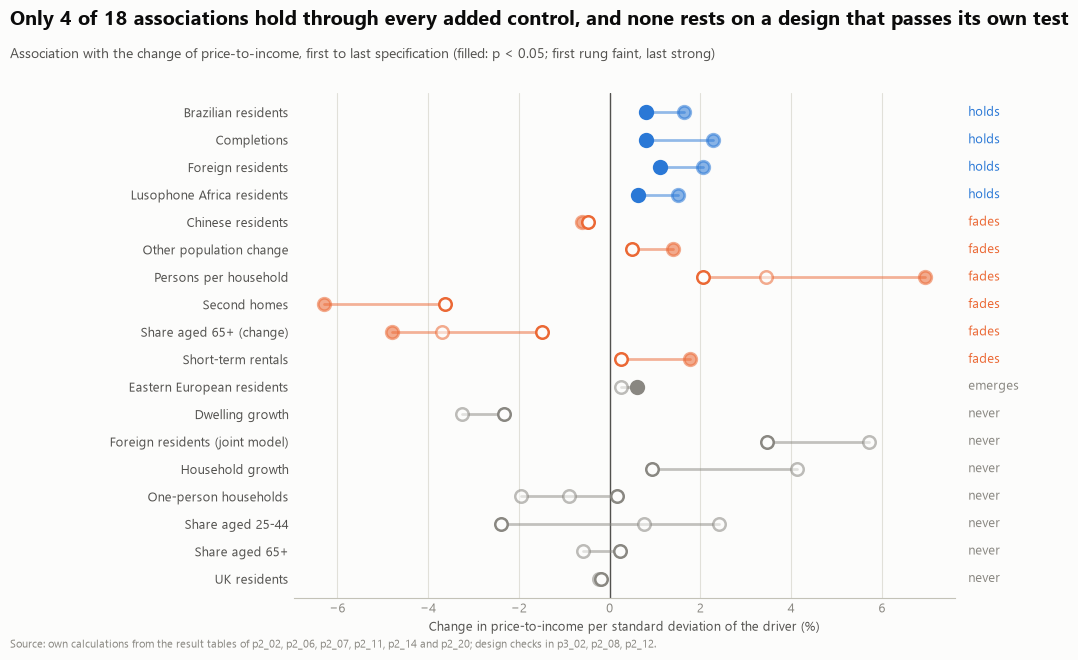

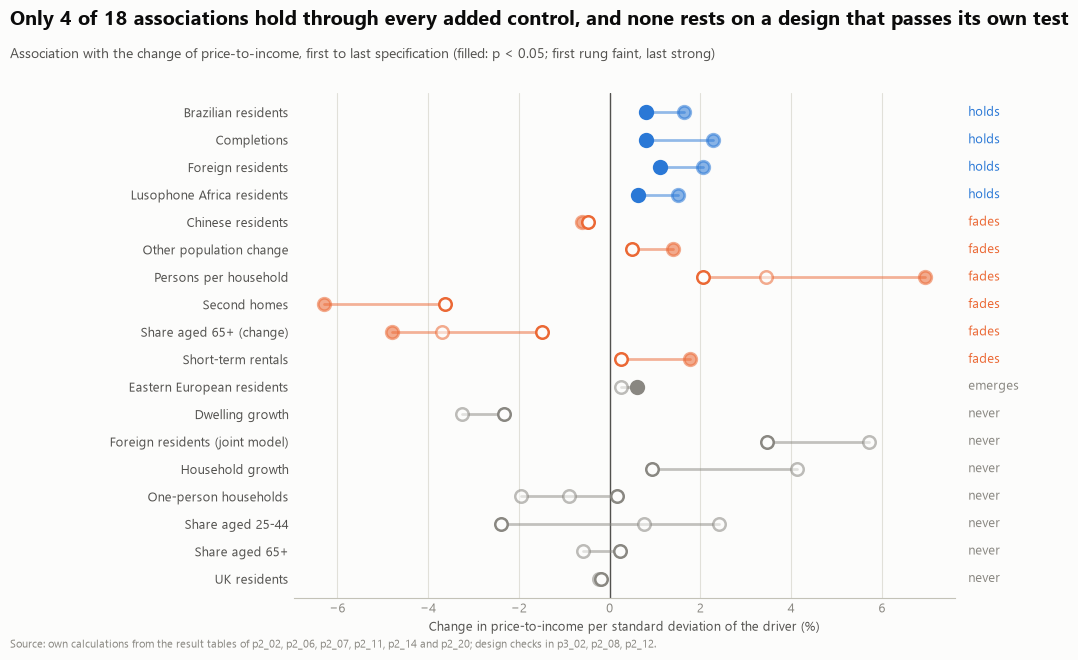

In [4]:
fig = charts.evidence_ladder(rung_detail, ladder)
style.save_fig(fig, "p2", "evidence_ladder")
fig

## Findings

1. **Four of 18 associations hold at every rung (M3).** In the panel with municipality and year effects, then municipality and
   region-year effects: foreign residents (p < 0.001 at both rungs; +2.0% then +1.1% of price-to-income per standard deviation),
   completions (+2.3%, +0.8%), Brazilian residents (+1.6%, +0.8%) and Lusophone Africa residents (+1.5%, +0.6%). Six fade (other
   population change, Chinese residents, second homes, the 65+ share, short-term rentals, persons per household), one emerges (Eastern
   European residents, only with region-year effects) and seven are never significant, among them household growth, dwelling growth,
   the 25-44 share, the one-person share and UK residents.
2. **What holds is regional, not mechanical.** The coefficient of every one that holds falls by a half to two thirds with region-year effects, which
   absorb where prices rose. Completions have a *positive* sign (more building where price-to-income rose), so it marks places that boomed,
   not supply that eased prices. The same foreign-resident change is not significant in the cross-section with every block in
   (p = 0.11, 0.21): the panel has the power, the cross-section does not.
3. **None of the three designs with a test of its own assumption is credibly causal.** The IMI event study rejects its pre-trend
   (p = 0.024) and its effect is not distinguishable from zero; the mortgage-rate timing test does not reject its placebo (p = 0.67) but finds
   no effect; credit growth rejects its placebo (next year's credit growth predicts this year's price growth, p = 0.003): credit follows prices.
   By the reading rule fixed in advance no relationship has a credible causal identification.
4. **What it would take.** A policy with a sharp rule change and a comparison group (not a national exemption that treats everyone from one
   date, as the youth IMT exemption does), transaction data by buyer and by municipality (INE publishes prices by buyer's residence but no
   counts), and a window long enough to test pre-trends; the project's municipal prices start in 2016.

**Limits.** Ladders compare the specifications each notebook chose, which differ in sample and in whether rental and income controls are in
(so rungs are not all nested); the standardisation is by the driver's within or cross-sectional standard deviation, as each table gives it; 18
drivers is a count of what was tested, not of what matters; p-values are not corrected for the number of tests; the outcome windows differ
slightly (2016-2023 panel, 2016-2024 cross-sections).